# 01 EDA: สำรวจข้อมูลดวงรายสัปดาห์ 4 เว็บ × 12 ราศี

**เจ้าของ:** Member 2 · **ข้อมูล:** `data/processed/horoscopes.csv` (สร้างโดย `src/build_dataset.py`)

**คำถามของโน้ตบุ๊กนี้:** ก่อนเริ่มวิเคราะห์จริง ข้อมูลหน้าตาเป็นอย่างไร
1. แต่ละเว็บและแต่ละราศีมีข้อมูลครบไหม
2. ความยาวข้อความต่างกัน**ตามเว็บ**หรือ**ตามราศี**
3. คำที่พบบ่อยของแต่ละเว็บคืออะไร
4. word cloud ของ 12 ราศีหน้าตาต่างกันไหม

**วิธี (L3 Visualization, L5 Data Preparation):** ใช้คอลัมน์ `text` (ตัดส่วนที่บอกราศีโดยตรงออกแล้ว) → `clean_text()` (ลบชื่อราศี) → `tokenize()` (ตัดคำ newmm และตัด stopword)
กราฟทั้งหมดบันทึกไว้ที่ `outputs/figures/01_*.png`

In [1]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from scipy.stats import kruskal
from wordcloud import WordCloud

# Make "src" importable whether the notebook runs from notebooks/ or the project folder
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.thai_text import STOPWORDS, THAI_FONT, ZODIAC_TH, clean_text, tokenize

FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Thai font for every chart (fonts/Sarabun-Regular.ttf)
font_manager.fontManager.addfont(THAI_FONT)
THAI_FONT_NAME = font_manager.FontProperties(fname=THAI_FONT).get_name()

# Quiet chart style: light grid, no top/right border, grey axis text
plt.rcParams.update({
    "font.family": THAI_FONT_NAME, "font.size": 11,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "normal",  # Sarabun: Regular only
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "savefig.dpi": 200, "savefig.bbox": "tight",
})

# One fixed color per website, used in EVERY notebook (colorblind-safe order, checked with a validator)
SITES = ["marumura", "sanook", "thairath", "kapook"]
SITE_COLORS = {"marumura": "#2a78d6", "sanook": "#eb6834", "thairath": "#1baf7a", "kapook": "#eda100"}
SIGNS = ["Aries", "Taurus", "Gemini", "Cancer", "Leo", "Virgo", "Libra", "Scorpio",
         "Sagittarius", "Capricorn", "Aquarius", "Pisces"]
SIGN_TH = {en: th for th, en in ZODIAC_TH.items()}  # "Aries" -> "เมษ"

## 1) โหลดข้อมูลและตัดคำ

In [2]:
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "horoscopes.csv")

# Tokenize once (about 20 s): all words, then the same list without stopwords
df["all_words"] = df["text"].apply(lambda t: tokenize(clean_text(t), remove_stopwords=False))
df["tokens"] = df["all_words"].apply(lambda ws: [w for w in ws if w not in STOPWORDS])
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["all_words"].str.len()
print(df.shape)
df[["source", "week", "zodiac", "text", "n_chars", "n_words"]].head(3)

(1233, 14)


,source,week,zodiac,text,n_chars,n_words
0,kapook,2026-05-18,Aries,เรื่องสำคัญของคุณในสัปดาห์นี้ อยู่ในห้วงอารมณ์...,807,156
1,kapook,2026-05-18,Taurus,เรื่องสำคัญของคุณในสัปดาห์นี้ หลายอย่างจะเต็มไ...,847,161
2,kapook,2026-05-18,Gemini,เรื่องสำคัญของคุณในสัปดาห์นี้ ช่วงของการจัดการ...,865,168


## 2) ข้อมูลครบไหม: จำนวนแถวต่อเว็บ × ราศี

In [3]:
coverage = pd.crosstab(df["source"], df["zodiac"]).reindex(index=SITES, columns=SIGNS)
coverage["รวม"] = coverage.sum(axis=1)
print("ทั้งหมด", len(df), "แถว,", df["week_monday"].nunique(), "สัปดาห์ (",
      df["week_monday"].min(), "ถึง", df["week_monday"].max(), ")")
coverage

ทั้งหมด 1233 แถว, 26 สัปดาห์ ( 2026-05-18 ถึง 2026-11-09 )


zodiac,Aries,Taurus,Gemini,Cancer,Leo,Virgo,Libra,Scorpio,Sagittarius,Capricorn,Aquarius,Pisces,รวม
source,,,,,,,,,,,,,
marumura,26,26,26,26,26,26,26,26,26,26,26,26,312
sanook,26,26,25,26,25,26,26,26,26,25,26,26,309
thairath,25,25,25,25,25,25,25,25,25,25,25,25,300
kapook,26,26,26,26,26,26,26,26,26,26,26,26,312


**จากตาราง พบว่า** ข้อมูลมีทั้งหมด 1,233 แถว ครอบคลุม 26 สัปดาห์ (18 พ.ค. ถึง 9 พ.ย. 2026)
- marumura และ kapook ครบ 312 แถว (26 สัปดาห์ × 12 ราศี)
- sanook ขาด 3 แถว (ราศีเมถุน ราศีสิงห์ และราศีมังกร อย่างละ 1 สัปดาห์) เพราะเว็บไม่มีบทความ หรือลิงก์เสีย
- thairath มี 25 สัปดาห์ เพราะเว็บไม่มีสัปดาห์ 1–7 พ.ย.

ทุกราศีจึงมีข้อมูลใกล้เคียงกัน (99–104 แถวต่อราศี) จำนวนข้อมูลที่ต่างกันจึงไม่ทำให้ผลการเปรียบเทียบระหว่างราศีเอนเอียง

## 3) ความยาวข้อความ: ต่างกันตามเว็บหรือตามราศี

In [4]:
length_table = df.groupby("source").agg(
    rows=("text", "size"),
    mean_words=("n_words", "mean"), median_words=("n_words", "median"),
    sd_words=("n_words", "std"), mean_chars=("n_chars", "mean"),
).reindex(SITES).round(1)

# Kruskal-Wallis test inside each site: does length differ between the 12 signs?
# (non-parametric version of one-way ANOVA; p < 0.05 = lengths differ by sign)
length_table["p_length_by_sign"] = [
    kruskal(*[g["n_words"] for _, g in df[df.source == s].groupby("zodiac")]).pvalue for s in SITES
]
length_table.round(3)

,rows,mean_words,median_words,sd_words,mean_chars,p_length_by_sign
source,,,,,,
marumura,312,123.7,121.0,27.4,526.6,0.351
sanook,309,305.0,297.0,50.7,1623.1,0.000
thairath,300,65.4,65.0,5.3,320.5,0.656
kapook,312,178.1,178.0,11.8,900.4,0.000


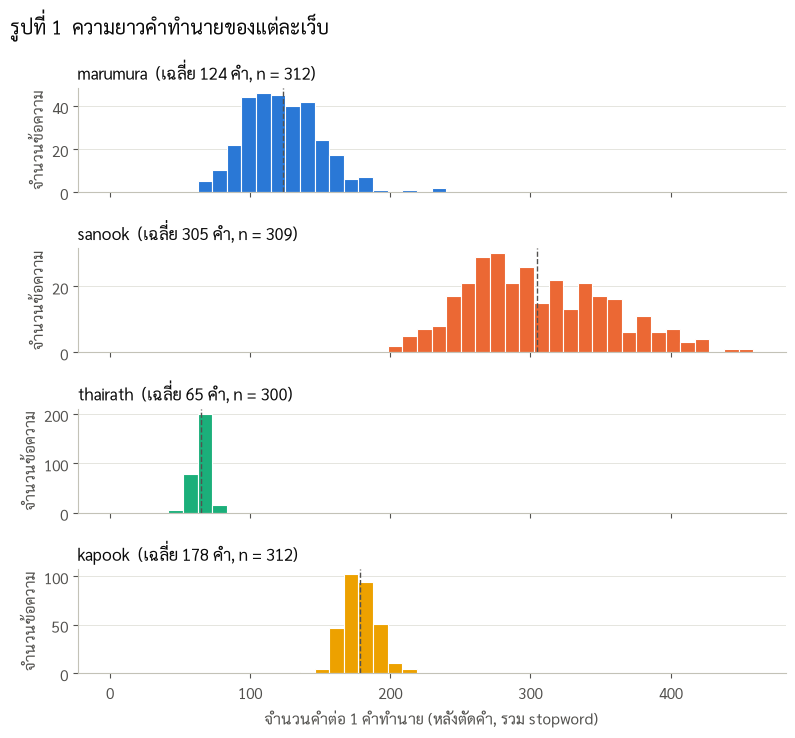

In [5]:
# Figure 1: word-count histogram, one panel per site, same x axis so sites compare directly
bins = np.linspace(0, df["n_words"].max() + 10, 45)
fig, axes = plt.subplots(len(SITES), 1, figsize=(8, 7.5), sharex=True)
for ax, site in zip(axes, SITES):
    x = df.loc[df.source == site, "n_words"]
    ax.hist(x, bins=bins, color=SITE_COLORS[site], edgecolor="white", linewidth=0.8)
    ax.axvline(x.mean(), color="#52514e", linewidth=1, linestyle="--")
    ax.set_title(f"{site}  (เฉลี่ย {x.mean():.0f} คำ, n = {len(x)})", loc="left")
    ax.set_ylabel("จำนวนข้อความ")
    ax.grid(axis="x", visible=False)
axes[-1].set_xlabel("จำนวนคำต่อ 1 คำทำนาย (หลังตัดคำ, รวม stopword)")
fig.suptitle("รูปที่ 1  ความยาวคำทำนายของแต่ละเว็บ", x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_length_hist_by_site.png")
plt.show()

**จากรูปที่ 1 พบว่า** ความยาวคำทำนายของแต่ละเว็บแยกกันชัดเจน แทบไม่ซ้อนทับกันเลย
- **thairath** สั้นที่สุด เฉลี่ย 65 คำ และเกือบทุกข้อความยาวเท่ากัน (SD = 5 คำ)
- **marumura** เฉลี่ย 124 คำ (SD = 27)
- **kapook** เฉลี่ย 178 คำ ยาวคงที่เช่นกัน (SD = 12) เพราะทุกราศีมี 6 หัวข้อเหมือนกัน
- **sanook** ยาวที่สุดและกระจายมากที่สุด เฉลี่ย 305 คำ (SD = 51)

**ความหมาย:** แต่ละเว็บเขียนตามกรอบความยาวของตัวเอง ถ้ารู้แค่ความยาวก็เดาได้เกือบถูกแล้วว่าเป็นเว็บไหน
จึงคาดว่าในโน้ตบุ๊ก 03 การทาย**เว็บ**จะง่าย ซึ่งเกิดจาก**รูปแบบการเขียน** ไม่ได้เกิดจากเนื้อหาคำทำนาย

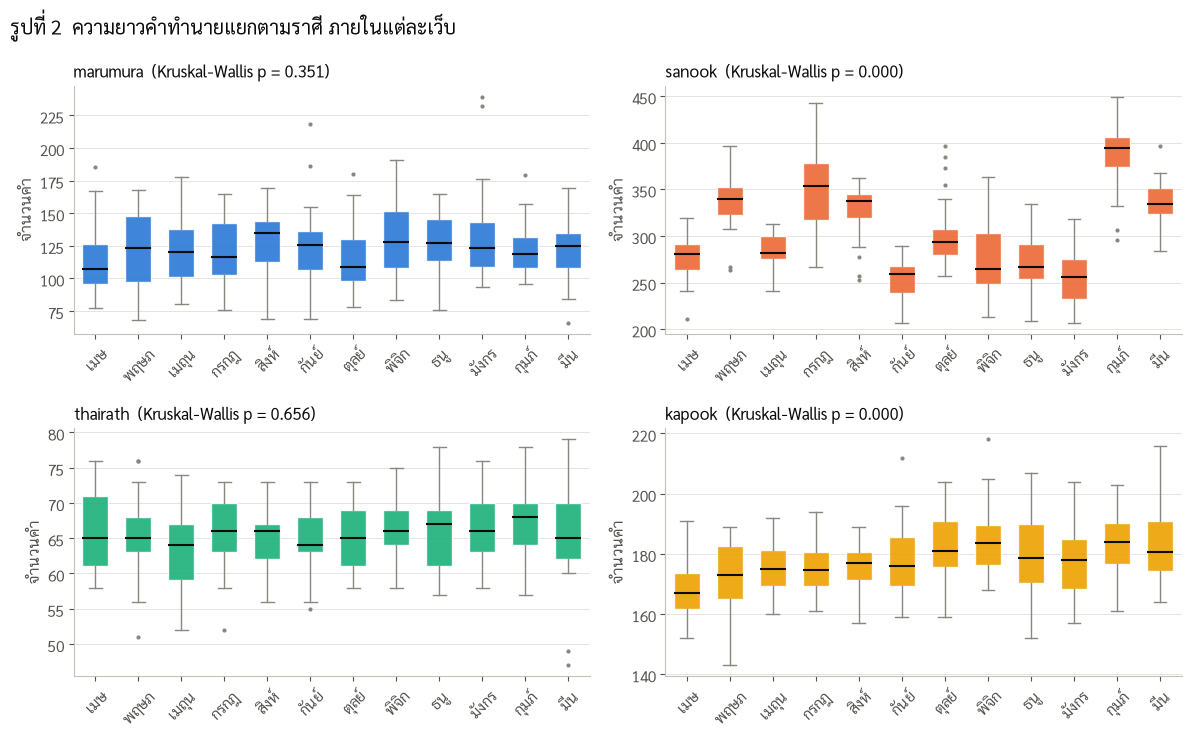

In [6]:
# Figure 2: word count by sign, one panel per site (each panel has its own y scale:
# the question is "do signs differ INSIDE a site?", not "which site is longer?")
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, site in zip(axes.flat, SITES):
    sub = df[df.source == site]
    data = [sub.loc[sub.zodiac == z, "n_words"] for z in SIGNS]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6,
                    medianprops={"color": "#0b0b0b", "linewidth": 1.5},
                    whiskerprops={"color": "#898781"}, capprops={"color": "#898781"},
                    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "#898781",
                                "markeredgecolor": "none"})
    for box in bp["boxes"]:
        box.set(facecolor=SITE_COLORS[site], edgecolor="white", alpha=0.9)
    p = length_table.loc[site, "p_length_by_sign"]
    ax.set_title(f"{site}  (Kruskal-Wallis p = {p:.3f})", loc="left")
    ax.set_xticks(range(1, 13), [SIGN_TH[z] for z in SIGNS], rotation=45)
    ax.set_ylabel("จำนวนคำ")
    ax.grid(axis="x", visible=False)
fig.suptitle("รูปที่ 2  ความยาวคำทำนายแยกตามราศี ภายในแต่ละเว็บ", x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_length_box_by_sign.png")
plt.show()

In [7]:
# Why do sanook and kapook lengths differ by sign? Two checks.
from scipy.stats import spearmanr

# sanook: how much of each sign's length is the reused "คำแนะนำ" section? (text minus text_strict)
san = df[df.source == "sanook"].assign(len_text=lambda d: d["text"].str.len(),
                                       len_strict=lambda d: d["text_strict"].str.len())
san["len_advice"] = san["len_text"] - san["len_strict"]
print("sanook: mean characters per sign")
display(san.groupby("zodiac")[["len_text", "len_strict", "len_advice"]].mean().reindex(SIGNS).round(0).T)
print("Kruskal-Wallis p (text):       ", kruskal(*[g["len_text"] for _, g in san.groupby("zodiac")]).pvalue)
print("Kruskal-Wallis p (text_strict):", kruskal(*[g["len_strict"] for _, g in san.groupby("zodiac")]).pvalue)

# kapook: one article lists the signs in order Aries -> Pisces. Are later signs longer?
kap = df[df.source == "kapook"]
rho, p = spearmanr(kap["zodiac"].map(SIGNS.index), kap["n_words"])
print(f"\nkapook: Spearman(sign position in the article, word count) = {rho:.2f}, p = {p:.1e}")

sanook: mean characters per sign


zodiac,Aries,Taurus,Gemini,Cancer,Leo,Virgo,Libra,Scorpio,Sagittarius,Capricorn,Aquarius,Pisces
len_text,1463.0,1819.0,1508.0,1841.0,1728.0,1339.0,1604.0,1490.0,1456.0,1388.0,2026.0,1806.0
len_strict,1086.0,999.0,1109.0,1016.0,946.0,970.0,1084.0,991.0,1058.0,1001.0,973.0,1038.0
len_advice,377.0,820.0,399.0,824.0,782.0,369.0,520.0,499.0,398.0,388.0,1053.0,768.0


Kruskal-Wallis p (text):        1.1319711204514596e-35
Kruskal-Wallis p (text_strict): 2.331639796075199e-08

kapook: Spearman(sign position in the article, word count) = 0.33, p = 2.1e-09


**จากรูปที่ 2 พบว่า**
- **marumura (p = 0.35) และ thairath (p = 0.66):** ความยาวไม่ต่างกันตามราศี (Kruskal-Wallis p > 0.05) ผู้เขียนเขียนทุกราศียาวพอๆ กัน
- **sanook (p < 0.001):** ต่างกันมาก เช่น ราศีกุมภ์ยาวเฉลี่ยประมาณ 395 คำ ส่วนราศีกันย์ประมาณ 260 คำ ตารางด้านบนแสดงว่าส่วนใหญ่มาจาก**ส่วน "คำแนะนำ"** ที่ใช้ซ้ำหลายสัปดาห์ ซึ่งยาว 369 ตัวอักษร (ราศีกันย์) ถึง 1,053 ตัวอักษร (ราศีกุมภ์)
  ถ้าใช้ `text_strict` ที่ตัดส่วนนี้ออก ความยาวจะใกล้กันมากขึ้น (946–1,109 ตัวอักษร) แต่ยังต่างกันอย่างมีนัยสำคัญ (p ≈ 2×10⁻⁸)
- **kapook (p < 0.001):** ต่างกันเล็กน้อย (ประมาณ 167–184 คำ) และราศีที่อยู่ท้ายบทความยาวกว่าราศีต้นบทความ (Spearman ρ = 0.33)
  น่าจะเป็นนิสัยของผู้เขียนที่เขียนยาวขึ้นเรื่อยๆ ตามลำดับในบทความ ไม่เกี่ยวกับตัวราศี

**ความหมาย:** ความยาวที่ต่างกันตามราศีมาจาก**โครงสร้างและนิสัยการเขียนของแต่ละเว็บ** ไม่ได้มาจากเนื้อหาคำทำนายที่ต่างกัน
**ข้อควรระวังสำหรับโน้ตบุ๊ก 03:** ความยาวของ sanook บอกใบ้ได้ว่าเป็นราศีไหน จึงควรรายงานผลการทายราศีทั้งแบบใช้ `text` และ `text_strict`

## 4) คำที่พบบ่อยของแต่ละเว็บ

stopword ของ PyThaiNLP ไม่ได้ตัดคำเชื่อม/คำทั่วไปบางคำที่พบบ่อยมากในดวง เช่น "ที่จะ", "วันที่", "ทำ", "เรื่อง"
ซึ่งทำให้ word cloud ทุกราศีมีแต่คำเหล่านี้ **ในโน้ตบุ๊กนี้จึงตัดเพิ่มเฉพาะ 4 คำนี้** (`EDA_EXTRA_STOPWORDS`)
ไม่ได้แก้ `src/thai_text.py` ถ้าทีมเห็นว่าควรตัดในทุกโน้ตบุ๊ก ค่อยเพิ่มเข้า `STOPWORDS` ทีหลัง

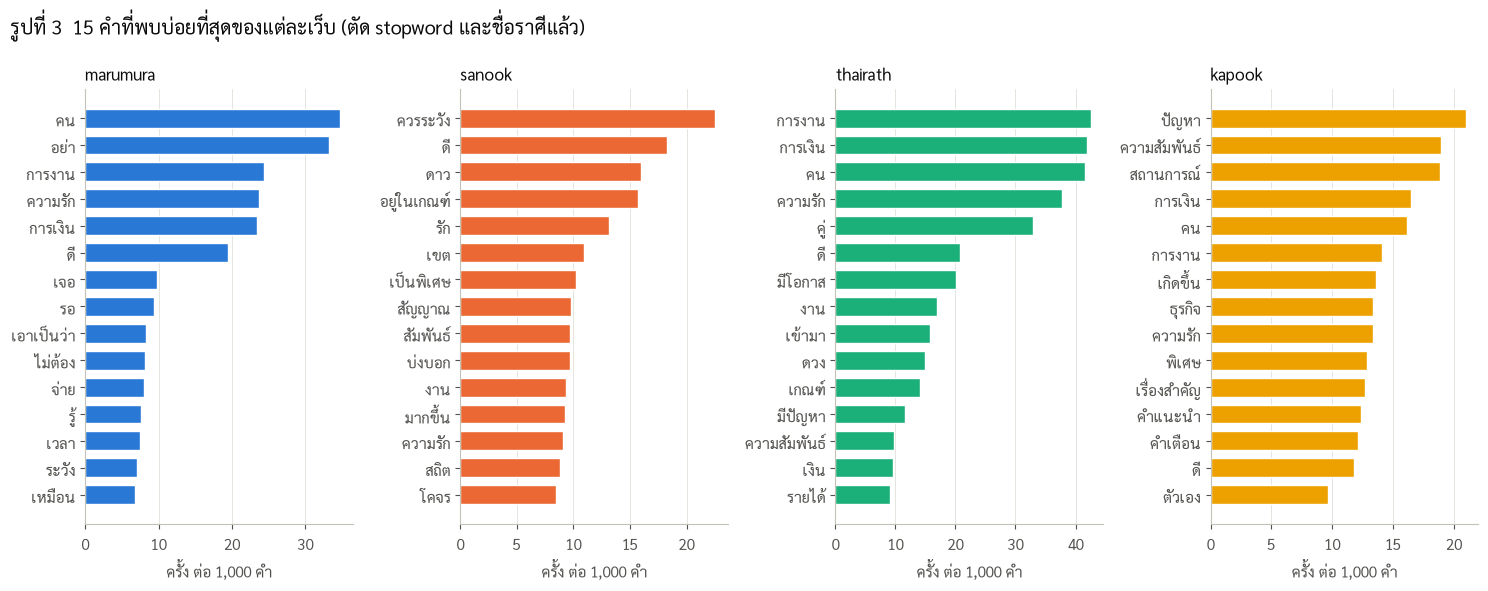

คำที่อยู่ใน top 15 ของทั้ง 4 เว็บ: ['ความรัก', 'ดี']


In [8]:
# Figure 3: top 15 words per site, as "times per 1,000 words" so long and short sites compare fairly
EDA_EXTRA_STOPWORDS = {"ที่จะ", "วันที่", "ทำ", "เรื่อง"}  # very common, carry no meaning (EDA only)
df["tokens"] = df["tokens"].apply(lambda ws: [w for w in ws if w not in EDA_EXTRA_STOPWORDS])
TOP_N = 15
fig, axes = plt.subplots(1, len(SITES), figsize=(15, 6))
top_words = {}
for ax, site in zip(axes, SITES):
    counts = Counter(w for ws in df.loc[df.source == site, "tokens"] for w in ws)
    total = sum(counts.values())
    top = counts.most_common(TOP_N)
    top_words[site] = [w for w, _ in top]
    words = [w for w, _ in top][::-1]
    rates = [c / total * 1000 for _, c in top][::-1]
    ax.barh(words, rates, color=SITE_COLORS[site], height=0.7, edgecolor="white", linewidth=1)
    ax.set_title(site, loc="left")
    ax.set_xlabel("ครั้ง ต่อ 1,000 คำ")
    ax.grid(axis="y", visible=False)
fig.suptitle(f"รูปที่ 3  {TOP_N} คำที่พบบ่อยที่สุดของแต่ละเว็บ (ตัด stopword และชื่อราศีแล้ว)",
             x=0.01, ha="left", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_top_words_by_site.png")
plt.show()

# How many of the top words are shared by all 4 sites?
shared = set.intersection(*[set(v) for v in top_words.values()])
print("คำที่อยู่ใน top", TOP_N, "ของทั้ง 4 เว็บ:", sorted(shared))

**จากรูปที่ 3 พบว่า** คำที่พบบ่อยของแต่ละเว็บต่างกันมาก และสะท้อน**สไตล์ของผู้เขียน**
- **marumura** ใช้ภาษาพูด เป็นกันเอง เช่น "อย่า", "เอาเป็นว่า", "ไม่ต้อง", "รอ", "รู้"
- **sanook** ใช้ศัพท์โหราศาสตร์ เช่น "ดาว", "เขต", "สถิต", "โคจร", "อยู่ในเกณฑ์", "สัญญาณ", "บ่งบอก"
- **thairath** คำที่พบบ่อยคือหัวข้อทั้ง 3 ของเว็บ (การงาน การเงิน ความรัก) และ "คู่" (คนมีคู่/คนโสด)
- **kapook** คำที่พบบ่อยคือหัวข้อทั้ง 6 ของเว็บ เช่น "ความสัมพันธ์", "สถานการณ์", "ธุรกิจ", "เรื่องสำคัญ", "คำแนะนำ", "คำเตือน"

มีแค่ 2 คำที่อยู่ใน top 15 ของทั้ง 4 เว็บ คือ "ความรัก" และ "ดี" แสดงว่า**แต่ละเว็บมีคลังคำของตัวเอง**
ส่วนหัวข้อที่ทุกเว็บพูดถึงคือ การงาน การเงิน และความรัก ซึ่งตรงกับวัตถุประสงค์ข้อ 2 (topic) จะวิเคราะห์ละเอียดในโน้ตบุ๊ก 04

## 5) Word cloud ของ 12 ราศี (รวมทุกเว็บ)

**หมายเหตุทางเทคนิค:** `WordCloud.to_image()` ใช้ Pillow วาดตัวอักษร ซึ่งในเครื่องนี้ไม่มีตัวจัดวางตัวอักษรไทย (libraqm)
สระบน/วรรณยุกต์จึงวางผิด เช่น "ที่จะ" กลายเป็น "ทีจะ" เราจึงให้ WordCloud **คำนวณตำแหน่งและขนาดคำ** (`wc.layout_`)
แล้วให้ **matplotlib วาดตัวอักษรเอง** ซึ่งวางสระและวรรณยุกต์ไทยได้ถูกต้อง (ฟังก์ชัน `draw_wordcloud`)

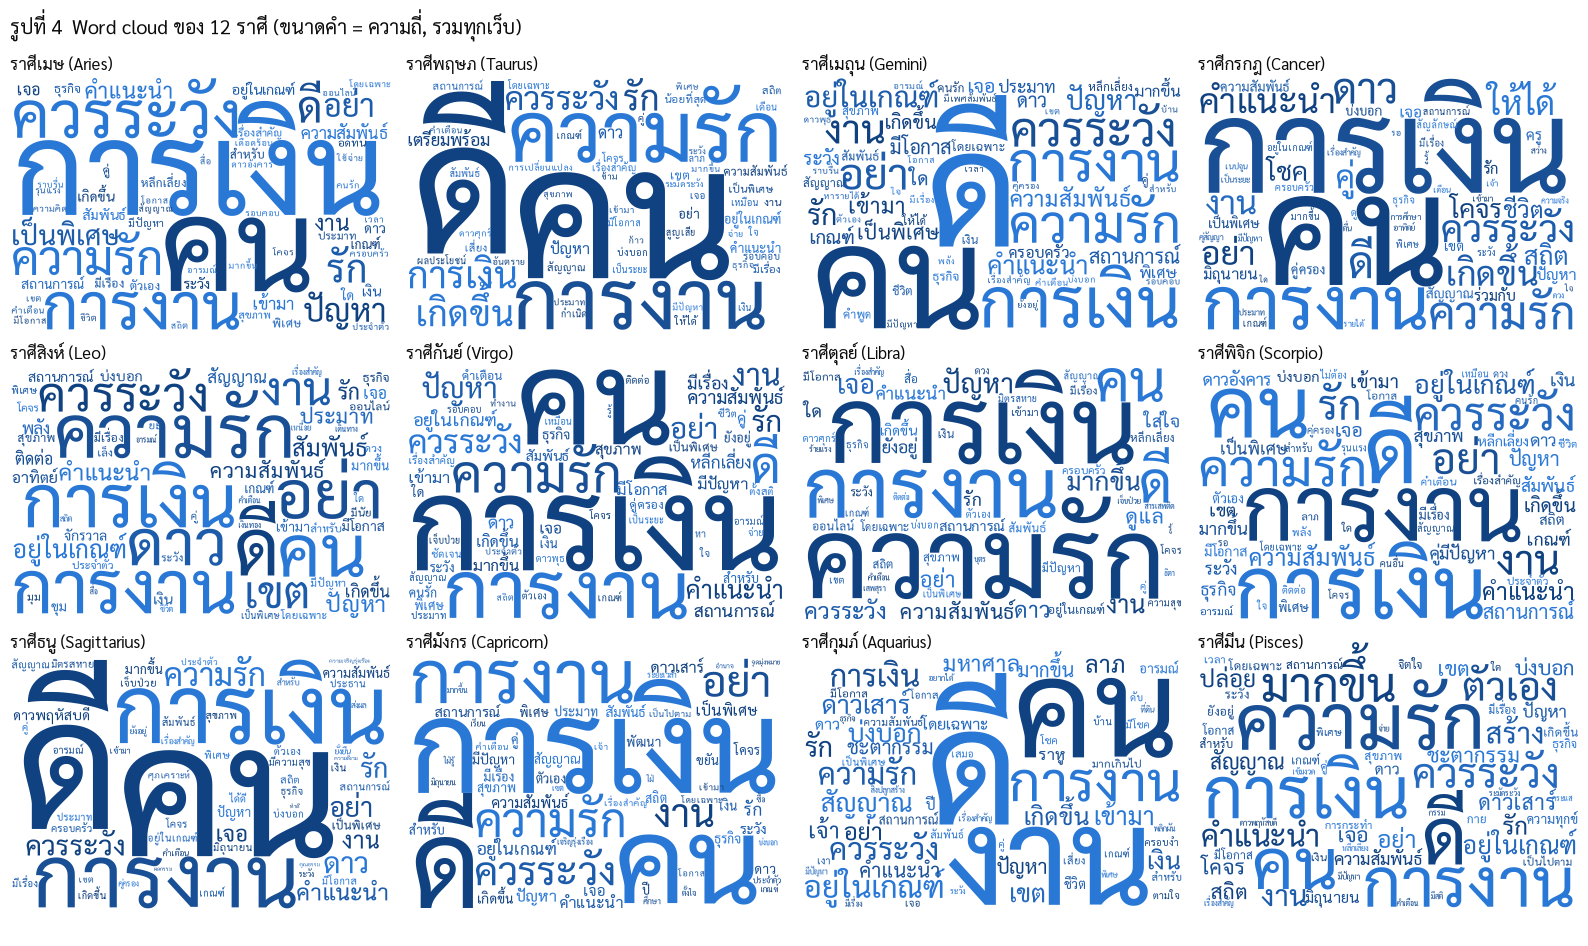

In [9]:
from PIL import ImageFont

# One blue family for every cloud: color carries no meaning here, only word size (= frequency) does
BLUES = ["#104281", "#184f95", "#1c5cab", "#256abf", "#2a78d6"]
def blue_color(*args, random_state=None, **kwargs):
    return BLUES[random_state.randint(0, len(BLUES) - 1)]

def draw_wordcloud(ax, wc):
    """Draw a WordCloud's layout with matplotlib text (correct Thai vowel/tone marks)."""
    ax.set_xlim(0, wc.width)
    ax.set_ylim(wc.height, 0)          # image coordinates: y goes down
    ax.set_aspect("equal")
    ax.axis("off")
    ax.apply_aspect()
    axes_width_inch = ax.get_position().width * ax.figure.get_figwidth()
    pt_per_px = axes_width_inch * 72 / wc.width      # 1 cloud pixel = this many points
    for (word, _), size, (y, x), _, color in wc.layout_:
        # In the WordCloud layout, y = top of the word's ink. matplotlib places text by its
        # baseline, so move down by the ink height above the baseline (measured with PIL).
        ink_top = ImageFont.truetype(THAI_FONT, size).getbbox(word, anchor="ls")[1]  # negative
        ax.text(x, y - ink_top, word, fontsize=size * pt_per_px, color=color,
                ha="left", va="baseline", fontfamily=THAI_FONT_NAME)

sign_counts = {z: Counter(w for ws in df.loc[df.zodiac == z, "tokens"] for w in ws) for z in SIGNS}
clouds = {z: WordCloud(font_path=THAI_FONT, width=600, height=400, max_words=60,
                       color_func=blue_color, random_state=42, prefer_horizontal=1.0,
                       ).generate_from_frequencies(sign_counts[z]) for z in SIGNS}

fig, axes = plt.subplots(3, 4, figsize=(16, 9.5))
for ax, z in zip(axes.flat, SIGNS):
    ax.set_title(f"ราศี{SIGN_TH[z]} ({z})", loc="left")
    ax.set_xlim(0, 600); ax.set_ylim(400, 0); ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("รูปที่ 4  Word cloud ของ 12 ราศี (ขนาดคำ = ความถี่, รวมทุกเว็บ)", x=0.01, ha="left", fontsize=14)
fig.tight_layout()                     # fix the panel sizes first, then draw text at the right size
for ax, z in zip(axes.flat, SIGNS):
    draw_wordcloud(ax, clouds[z])
fig.savefig(FIG_DIR / "01_wordcloud_by_sign.png")
plt.show()

In [10]:
# Numbers behind Figure 4: are the top-20 word lists of the 12 SIGNS more alike than those of the 4 SITES?
# Jaccard = |A and B| / |A or B|  (1 = same 20 words, 0 = no word in common)
def top20_jaccard(groups, column):
    top = {g: {w for w, _ in Counter(w for ws in df.loc[df[column] == g, "tokens"] for w in ws).most_common(20)}
           for g in groups}
    pairs = [len(top[a] & top[b]) / len(top[a] | top[b]) for i, a in enumerate(groups) for b in groups[i + 1:]]
    return top, pairs

sign_top, sign_pairs = top20_jaccard(SIGNS, "zodiac")
site_top, site_pairs = top20_jaccard(SITES, "source")
print(f"คำที่อยู่ใน top 20 ของทั้ง 12 ราศี ({len(set.intersection(*sign_top.values()))} คำ):",
      sorted(set.intersection(*sign_top.values())))
print(f"คำที่อยู่ใน top 20 ของทั้ง 4 เว็บ  ({len(set.intersection(*site_top.values()))} คำ):",
      sorted(set.intersection(*site_top.values())))
pd.DataFrame({
    "เปรียบเทียบ": ["ราศี vs ราศี (66 คู่)", "เว็บ vs เว็บ (6 คู่)"],
    "Jaccard เฉลี่ย": [np.mean(sign_pairs), np.mean(site_pairs)],
    "ต่ำสุด": [min(sign_pairs), min(site_pairs)], "สูงสุด": [max(sign_pairs), max(site_pairs)],
}).round(2)

คำที่อยู่ใน top 20 ของทั้ง 12 ราศี (8 คำ): ['การงาน', 'การเงิน', 'คน', 'ควรระวัง', 'ความรัก', 'งาน', 'ดี', 'อย่า']
คำที่อยู่ใน top 20 ของทั้ง 4 เว็บ  (5 คำ): ['การงาน', 'การเงิน', 'ความรัก', 'งาน', 'ดี']


,เปรียบเทียบ,Jaccard เฉลี่ย,ต่ำสุด,สูงสุด
0,ราศี vs ราศี (66 คู่),0.53,0.29,0.74
1,เว็บ vs เว็บ (6 คู่),0.20,0.14,0.29


**จากรูปที่ 4 พบว่า** word cloud ทั้ง 12 ราศี**หน้าตาเกือบเหมือนกัน** คำใหญ่ที่สุดของทุกราศีคือ "การเงิน", "การงาน", "ความรัก", "คน", "ดี" และ "ควรระวัง"
มี 8 คำที่อยู่ใน top 20 ของ**ทุก**ราศี และเมื่อวัดความเหมือนของรายการคำ top 20 ด้วย Jaccard:
- **ระหว่างราศี** เฉลี่ย **0.53** (คู่ที่ต่างกันที่สุดได้ 0.29)
- **ระหว่างเว็บ** เฉลี่ย **0.20** (คู่ที่เหมือนกันที่สุดได้แค่ 0.29)

เว็บคู่ที่เหมือนกันที่สุดจึงเหมือนกันแค่เท่ากับราศีคู่ที่ต่างกันที่สุด แปลว่า**คำที่ใช้แตกต่างตามคนเขียน มากกว่าแตกต่างตามราศี**
คำเฉพาะราศีที่พอเห็นได้ส่วนใหญ่เป็นชื่อดาว เช่น "ดาวเสาร์" ในราศีมังกร ราศีกุมภ์ และราศีมีน หรือ "ดาวอังคาร" ในราศีพิจิกและราศีเมษ ซึ่งมาจากศัพท์โหราศาสตร์ของ sanook ที่ผูกดาวประจำราศีไว้กับราศีนั้น ไม่ได้เป็นคำทำนายที่ต่างกัน

*ข้อจำกัด:* นี่เป็นการดูคร่าวๆ จากคำที่พบบ่อยเท่านั้น การวัดจริงจะทำในโน้ตบุ๊ก 02 (TF-IDF + cosine) และ 03 (classification)

## สรุปผล EDA

1. **ข้อมูลครบเกือบทั้งหมด** มี 1,233 แถวจาก 4 เว็บ × 12 ราศี × 25–26 สัปดาห์ แต่ละราศีมีจำนวนข้อมูลใกล้กัน
2. **แต่ละเว็บมีลายมือของตัวเองชัดเจน** ทั้งความยาว (รูปที่ 1: เฉลี่ย 65 ถึง 305 คำ) และคำที่ใช้ (รูปที่ 3: มีคำร่วมกันแค่ 2 คำใน top 15)
3. **ราศีต่างๆ หน้าตาคล้ายกันมาก** word cloud ทั้ง 12 ราศีเหมือนกัน (รูปที่ 4) และรายการคำ top 20 ระหว่างราศีเหมือนกันมากกว่าระหว่างเว็บ (Jaccard 0.53 เทียบกับ 0.20)
4. **ความยาวที่ต่างกันตามราศีมาจากโครงสร้างของเว็บ** ได้แก่ส่วนคำแนะนำของ sanook และลำดับราศีในบทความของ kapook ไม่ได้มาจากเนื้อหา (รูปที่ 2)

**เชื่อมกับคำถามวิจัย:** ผลเบื้องต้นสอดคล้องกับ **Barnum effect** คือข้อความแตกต่างตาม**ผู้เขียน**มากกว่าตาม**ราศี**
แต่ยังเป็นแค่ EDA ต้องยืนยันด้วยโน้ตบุ๊ก 02 (similarity) และ 03 (classification: ทายราศีเทียบกับทายเว็บ)

**ข้อแนะนำสำหรับโน้ตบุ๊กถัดไป:**
- 02/03: รายงานผลทั้งแบบ `text` และ `text_strict` และแบบที่ตัด `near_duplicate` ออก
- 03: ถ้าทายเว็บได้แม่นมาก อาจเป็นเพราะความยาวและหัวข้อของแต่ละเว็บ ควรเขียนอธิบายไว้ในรายงาน
- ทีมอาจพิจารณาเพิ่ม "ที่จะ", "วันที่", "ทำ", "เรื่อง" เข้า `STOPWORDS` ใน `src/thai_text.py`

**รูปที่บันทึกไว้ (ใช้ในรายงาน):** `outputs/figures/01_length_hist_by_site.png`, `01_length_box_by_sign.png`, `01_top_words_by_site.png`, `01_wordcloud_by_sign.png`